# Milestone 2 – Baseline Generation (`03_generate`)

Generates images from the **saved text embeddings** with a pinned Stable Diffusion checkpoint and runs the Milestone 2 sweeps (classifier-free guidance scale, scheduler, step count). The same notebook runs both models: set `MODEL_TAG` in the config cell (`sd15` on one Colab account, `sd21` on the other).

**Inputs**
- `data/prompt_set_m2.csv` (from `01_eval_sets`): 10 prompts with `image_id`, `category`, `caption`, `emb_row`
- `embeddings/text_embeddings_{sd15,sd21}_caption.pt` (from `02_text_embeddings_*`)
- `requirements.txt`

**Outputs** (all tagged with `RUN_TAG`)
- `results/milestone2/images/<RUN_TAG>/*.png`: one image per prompt × setting, with the settings in the filename
- `results/milestone2/run_log_<RUN_TAG>.csv`: one row per image (settings, seed, time, GPU memory). `clip_score` is left empty for the evaluation lead
- `results/milestone2/config_<RUN_TAG>.json`: fixed run settings, checked on every resume
- `results/milestone2/run_log.csv`: merge of every `run_log_*.csv` (rebuilt by the last section)
- `results/milestone2/baseline_grid_<RUN_TAG>.png`, `strip_guidance_<RUN_TAG>.png`, `strip_scheduler_<RUN_TAG>.png`: first set of generated images

**How the text encoder meets the diffusion model**: the CLIP text encoder (ViT-L/14 for SD 1.5, OpenCLIP ViT-H for SD 2.1) turns each caption into a 77-token embedding sequence. The UNet reads that sequence through cross-attention at every denoising step. Because the embeddings were saved in `02`, this notebook passes them to the pipeline as `prompt_embeds` instead of re-encoding text. A check below confirms a saved embedding matches what the pinned encoder produces now.

**Sweeps** (baseline = DDIM, 30 steps, guidance 7.5; the two sweeps share this point, so it is generated once)
- guidance: 6 values × 10 prompts, scheduler and steps fixed at baseline
- steps × scheduler: 4 schedulers × 4 step counts × 10 prompts, guidance fixed at baseline
- 210 unique images per model; roughly 15–20 min on a T4

**Run order**: needs a GPU runtime (T4). First run with `RUN_SWEEPS = ["baseline"]` and check the grid, then run all. If the session disconnects, run all again: finished images are skipped. If pip changes any package in the first cell, restart the session and run all again.

## 1. Setup and config
Mounts the shared Drive folder and installs the pinned versions from `requirements.txt`, as in `01`/`02`. Everything that changes between runs lives in the config cell. `RUN_TAG` names every output, so a changed setup gets a new `RUN_VERSION` rather than overwriting old images.

In [18]:
from pathlib import Path
from importlib.metadata import version


try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path("/content/drive/MyDrive/IE7615_Project2")
except ImportError:
    ROOT = Path("./IE7615_Project2")

REQ = ROOT / "requirements.txt"
if REQ.exists():
    PINS = " ".join(l for l in REQ.read_text().split() if not l.startswith(("torch==", "torchvision==")))
    !pip -q install {PINS} jedi
    !pip -q uninstall -y torchvision
print(REQ.read_text())

torch_pin = next(l for l in REQ.read_text().split() if l.startswith("torch=="))
TV_VERSION = f"0.{int(torch_pin.split('==')[1].split('.')[1]) + 15}.0"
!pip -q install "torchvision=={TV_VERSION}"
!pip check

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0

No broken requirements found.


In [19]:
import subprocess, sys

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return r.returncode == 0, (r.stdout + r.stderr).strip().splitlines()[-1:]

TEST = f'{sys.executable} -c "from transformers import CLIPImageProcessor; from diffusers import StableDiffusionPipeline"'
ok, tail = sh(TEST)
print("imports work:", ok, tail)
fixed = False

if not ok:
    sh(f"{sys.executable} -m pip -q uninstall -y torchvision")
    ok, tail = sh(TEST); fixed = True
    print("after removing torchvision:", ok, tail)

if not ok:
    _, v = sh(f'{sys.executable} -c "import torch; print(torch.__version__)"')
    minor = int(v[0].split(".")[1])
    sh(f"{sys.executable} -m pip -q install --no-deps --force-reinstall torchvision==0.{minor + 15}.0")
    ok, tail = sh(TEST)
    print(f"after installing torchvision 0.{minor + 15}.0:", ok, tail)

assert ok, "Still failing: paste the three lines printed above"
if fixed:
    print("FIXED: Runtime > Restart session, then run all again (this cell should then print 'imports work: True')")

imports work: True []


In [20]:
import csv, json, os, time
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import transformers
print("torch", torch.__version__)
import traceback
try:
    from transformers import CLIPImageProcessor
except Exception:
    traceback.print_exc()
    raise SystemExit("CLIPImageProcessor import failed: paste the traceback above to the team.")

import diffusers
from diffusers import (StableDiffusionPipeline, PNDMScheduler, DDIMScheduler,
                       EulerDiscreteScheduler, DPMSolverMultistepScheduler)

assert torch.cuda.is_available(), "Switch the runtime to a GPU (T4)"
DEVICE = "cuda"
print(torch.cuda.get_device_name(0), "| torch", torch.__version__,
      "| diffusers", diffusers.__version__, "| transformers", transformers.__version__)

torch 2.11.0+cu130
Tesla T4 | torch 2.11.0+cu130 | diffusers 0.42.1 | transformers 5.22.0


In [21]:
#config
MODEL_TAG   = "sd15"              # "sd15" on one account, "sd21" on the other
RUN_VERSION = "v1"
RUN_TAG     = f"m2_{MODEL_TAG}_{RUN_VERSION}"
CAPTION_COL = "caption"
OVERWRITE   = False

#pinned checkpoints (must match the ones used in 02)
CHECKPOINTS = {"sd15": "stable-diffusion-v1-5/stable-diffusion-v1-5",
               "sd21": "sd2-community/stable-diffusion-2-1-base"}
SEED   = 42                       # as in 02: one CUDA-generator seed for every image
HEIGHT = WIDTH = 512
DTYPE  = "float16"

#sweeps
BASELINE        = {"scheduler": "ddim", "steps": 30, "guidance": 7.5}
GUIDANCE_VALUES = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]     # 1.0 = no guidance
STEP_VALUES     = [10, 20, 30, 50]
SCHEDULER_NAMES = ["pndm", "ddim", "euler", "dpmpp_2m"]
RUN_SWEEPS      = ["baseline", "guidance", "steps_x_scheduler"]
LIMIT_PROMPTS   = None

STRIP_PROMPT_GUIDANCE  = 27972    # colour_binding: one prompt across guidance values
STRIP_PROMPT_SCHEDULER = 1761     # counting: one prompt across schedulers

#run_log columns
LOG_COLUMNS = ["run_tag", "model_tag", "checkpoint", "revision", "image_id", "category", "emb_row",
               "scheduler", "steps", "guidance", "seed", "height", "width", "dtype",
               "filename", "gen_time_s", "peak_gpu_mem_gb", "gpu_name", "timestamp", "clip_score"]

DATA        = ROOT / "data"
EMB_DIR     = ROOT / "embeddings"
M2_RESULTS  = ROOT / "results" / "milestone2"
IMG_DIR     = M2_RESULTS / "images" / RUN_TAG
IMG_DIR.mkdir(parents=True, exist_ok=True)

PROMPT_FILE = DATA / "prompt_set_m2.csv"
EMB_FILE    = EMB_DIR / f"text_embeddings_{MODEL_TAG}_{CAPTION_COL}.pt"
RUN_LOG_RUN = M2_RESULTS / f"run_log_{RUN_TAG}.csv"
RUN_LOG     = M2_RESULTS / "run_log.csv"
CFG_FILE    = M2_RESULTS / f"config_{RUN_TAG}.json"

assert BASELINE["scheduler"] in SCHEDULER_NAMES
assert BASELINE["steps"] in STEP_VALUES and BASELINE["guidance"] in GUIDANCE_VALUES, \
    "baseline must lie inside both sweeps so they share one point"
print("run tag:", RUN_TAG)

run tag: m2_sd15_v1


## 2. Load prompt set and saved embeddings
`emb_row` is the row index into the embedding file. The check compares the saved image IDs with the prompt set so a row can never point at the wrong caption. Only the 10 needed rows are kept in memory.

In [22]:
prompts = pd.read_csv(PROMPT_FILE)
if LIMIT_PROMPTS:
    prompts = prompts.head(LIMIT_PROMPTS)
prompts["seed"] = SEED
print(len(prompts), "prompts")

emb = torch.load(EMB_FILE, map_location="cpu")
print({k: (tuple(v.shape) if torch.is_tensor(v) else type(v).__name__) for k, v in emb.items()})

for k in ("image_ids", "hidden", "uncond_hidden", "checkpoint", "revision"):
    assert k in emb, f"{EMB_FILE.name} has no '{k}' (02 saves: image_ids, hidden, pooled, uncond_hidden, checkpoint, revision, caption_col)"
assert emb["hidden"].shape[0] == len(emb["image_ids"]) and emb["uncond_hidden"].shape[0] == 1

assert emb["checkpoint"] == CHECKPOINTS[MODEL_TAG], f"embeddings were made with {emb['checkpoint']}"
CHECKPOINT, REVISION = emb["checkpoint"], emb["revision"]
for r in prompts.itertuples():
    assert emb["image_ids"][r.emb_row] == r.image_id, f"emb_row mismatch for image {r.image_id}"

cond_rows = {int(r): emb["hidden"][int(r)].unsqueeze(0).clone() for r in prompts["emb_row"]}
UNCOND_SAVED = emb["uncond_hidden"].clone()
del emb
print("checkpoint:", CHECKPOINT, "| revision:", REVISION[:10])
prompts

10 prompts
{'image_ids': 'list', 'hidden': (2000, 77, 768), 'pooled': (2000, 768), 'uncond_hidden': (1, 77, 768), 'checkpoint': 'str', 'revision': 'str', 'caption_col': 'str'}
checkpoint: stable-diffusion-v1-5/stable-diffusion-v1-5 | revision: 451f4fe161


,image_id,category,caption,emb_row,file_path,seed
0,1761,counting,Two planes flying in the sky over a bridge.,10,processed_512/000000001761.png,42
1,97924,people_action,Three people are loading a horse into a horse ...,343,processed_512/000000097924.png,42
2,25181,spatial_relation,A train station with an awning is depicted wit...,114,processed_512/000000025181.png,42
3,3661,simple_scene,A bunch of bananas sitting on top of a wooden ...,21,processed_512/000000003661.png,42
4,5600,two_objects,A pan filled with onions sitting next to a pan...,33,processed_512/000000005600.png,42
5,27972,colour_binding,A man in a red shirt rides a yellow surfboard ...,120,processed_512/000000027972.png,42
6,214200,visible_text,"A red stop sign that reads "" Eating Animals "" ...",763,processed_512/000000214200.png,42
7,12670,crowd,A crowd of people standing around each other.,69,processed_512/000000012670.png,42
8,88269,food_closeup,A plate holding a grilled cheese sandwich and ...,306,processed_512/000000088269.png,42
9,7574,cluttered_indoor,A kitchen with a very messy counter space.,43,processed_512/000000007574.png,42


## 3. Load the pinned pipeline
Loads the checkpoint at the exact revision recorded in the embeddings file. The safety checker is off: it adds time and memory to every timing and can replace an image with black, which would break the comparison. COCO captions are benign.

Two checks follow. First, a saved embedding is compared with the one the loaded text encoder produces now (cosine similarity), which confirms the encoder and checkpoint match `02`. Second, the empty-prompt embedding used for classifier-free guidance is the one 02 saved (`uncond_hidden`), checked the same way.

In [23]:
pipe = StableDiffusionPipeline.from_pretrained(
    CHECKPOINT, revision=REVISION, dtype=getattr(torch, DTYPE),
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
DEFAULT_SCHEDULER = pipe.scheduler                # what 02 used for its samples
BASE_SCHED_CFG = dict(pipe.scheduler.config)
print("loaded; default scheduler:", type(pipe.scheduler).__name__)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

loaded; default scheduler: PNDMScheduler


In [24]:
first = prompts.iloc[0]
with torch.no_grad():
    fresh = pipe.encode_prompt(first["caption"], DEVICE, 1, False)[0]
saved = cond_rows[int(first["emb_row"])].to(DEVICE, fresh.dtype)
cos = torch.nn.functional.cosine_similarity(fresh.flatten().float(), saved.flatten().float(), dim=0).item()
print(f"saved vs fresh embedding for image {first['image_id']}: cosine = {cos:.5f}, shape {tuple(fresh.shape)}")
assert cos > 0.999, "Saved embeddings do not match this encoder; check checkpoint/revision against 02"

with torch.no_grad():
    fresh_u = pipe.encode_prompt("", DEVICE, 1, False)[0]
UNCOND = UNCOND_SAVED.to(DEVICE, fresh.dtype)
cos_u = torch.nn.functional.cosine_similarity(fresh_u.flatten().float(), UNCOND.flatten().float(), dim=0).item()
print(f"saved vs fresh empty-prompt embedding: cosine = {cos_u:.5f}")
assert cos_u > 0.999
cond = {k: v.to(DEVICE, UNCOND.dtype) for k, v in cond_rows.items()}
del fresh, saved, fresh_u

saved vs fresh embedding for image 1761: cosine = 1.00000, shape (1, 77, 768)
saved vs fresh empty-prompt embedding: cosine = 1.00000


## 4. Schedulers by name
`set_scheduler` swaps the noise scheduler (sampler and timestep spacing) while keeping the checkpoint's trained noise schedule (betas) unchanged, so the schedulers are compared on the same model. Names: `pndm` (SD 1.5 default), `ddim`, `euler`, `dpmpp_2m` (DPM-Solver++ multistep).

**Guidance**: at each step the UNet runs with the caption embedding and the empty embedding, and the prediction is `eps = eps_uncond + w · (eps_cond − eps_uncond)`. `w = 1.0` turns guidance off (pure conditional generation); higher values push the image toward the caption at a cost in diversity and, past some point, in image quality.

In [25]:
SCHEDULERS = {"pndm": PNDMScheduler, "ddim": DDIMScheduler,
              "euler": EulerDiscreteScheduler, "dpmpp_2m": DPMSolverMultistepScheduler}
assert set(SCHEDULER_NAMES) <= set(SCHEDULERS)

def set_scheduler(name):
    pipe.scheduler = SCHEDULERS[name].from_config(BASE_SCHED_CFG)

for n in SCHEDULER_NAMES:
    set_scheduler(n)
    print(f"{n:9s} -> {type(pipe.scheduler).__name__}")

pndm      -> PNDMScheduler
ddim      -> DDIMScheduler
euler     -> EulerDiscreteScheduler
dpmpp_2m  -> DPMSolverMultistepScheduler


## 4b. Reproduce the Milestone 1 samples
02 generated its sample images with the checkpoint's default scheduler, 30 steps, guidance 7.5, a CUDA generator seeded 42, and the saved embeddings. This cell repeats that on the M1 prompts that are in the prompt set and compares with the saved `sample_<tag>_caption_<id>.png` files. If they agree, the pipeline here matches 02 and the M2 images line up with M1. A small difference is possible if the GPU type differs from 02's (a T4).

In [26]:
M1_RESULTS = ROOT / "results" / "milestone1"
pipe.scheduler = DEFAULT_SCHEDULER

def m1_gen(r):
    g = torch.Generator(DEVICE).manual_seed(SEED)
    with torch.no_grad():
        return pipe(prompt_embeds=cond[int(r.emb_row)], negative_prompt_embeds=UNCOND, num_inference_steps=30,
                    guidance_scale=7.5, generator=g).images[0]

def pix(a, b):
    d = np.abs(np.asarray(a, dtype=int) - np.asarray(b, dtype=int))
    return d.mean(), (d.max(axis=-1) > 10).mean() * 100

r0 = next(prompts.itertuples())
m, pct = pix(m1_gen(r0), m1_gen(r0))
print(f"same image generated twice here: mean diff {m:.3f}, {pct:.2f}% of pixels differ by >10")

checked = []
for r in prompts.itertuples():
    p = M1_RESULTS / f"sample_{MODEL_TAG}_{CAPTION_COL}_{r.image_id}.png"
    if p.exists():
        m, pct = pix(m1_gen(r), Image.open(p).convert("RGB"))
        checked.append(m)
        print(f"image {r.image_id}: mean diff vs M1 = {m:.3f}, {pct:.2f}% of pixels differ by >10")
print("default scheduler:", type(DEFAULT_SCHEDULER).__name__)
if checked:
    print("OK: matches M1 up to GPU/library rounding (02 saw mean 1.9-2.0 for the same effect)"
          if max(checked) < 5 else "WARNING: far from M1; compare scheduler, seed, dtype and embeddings with 02")

same image generated twice here: mean diff 0.000, 0.00% of pixels differ by >10
image 1761: mean diff vs M1 = 0.957, 0.94% of pixels differ by >10
image 97924: mean diff vs M1 = 2.674, 6.76% of pixels differ by >10
image 25181: mean diff vs M1 = 1.971, 4.57% of pixels differ by >10
image 3661: mean diff vs M1 = 0.729, 0.55% of pixels differ by >10
image 5600: mean diff vs M1 = 1.998, 5.74% of pixels differ by >10
default scheduler: PNDMScheduler
OK: matches M1 up to GPU/library rounding (02 saw mean 1.9-2.0 for the same effect)


## 5. Build the job list
Settings come from the sweeps in the config; duplicates (the shared baseline point) are removed. Filenames carry every setting, so the images are comparable without opening the log:

`<RUN_TAG>__id<image_id>__<scheduler>__s<steps>__g<guidance>__seed<seed>.png`

Jobs are sorted by scheduler so the scheduler is swapped as rarely as possible.

In [27]:
def fname(image_id, scheduler, steps, guidance, seed):
    return f"{RUN_TAG}__id{image_id}__{scheduler}__s{steps:02d}__g{guidance:04.1f}__seed{seed}.png"

settings = []
if "baseline" in RUN_SWEEPS:
    settings.append((BASELINE["scheduler"], BASELINE["steps"], BASELINE["guidance"]))
if "guidance" in RUN_SWEEPS:
    settings += [(BASELINE["scheduler"], BASELINE["steps"], g) for g in GUIDANCE_VALUES]
if "steps_x_scheduler" in RUN_SWEEPS:
    settings += [(sc, st, BASELINE["guidance"]) for sc in SCHEDULER_NAMES for st in STEP_VALUES]
settings = sorted(set(settings), key=lambda s: (SCHEDULER_NAMES.index(s[0]), s[1], s[2]))

jobs = [dict(scheduler=sc, steps=st, guidance=g, image_id=int(r.image_id), category=r.category,
             emb_row=int(r.emb_row), seed=int(r.seed),
             filename=fname(int(r.image_id), sc, st, g, int(r.seed)))
        for (sc, st, g) in settings for r in prompts.itertuples()]
assert len({j["filename"] for j in jobs}) == len(jobs)
print(f"{len(settings)} settings x {len(prompts)} prompts = {len(jobs)} images")

21 settings x 10 prompts = 210 images


## 6. Run config and log format
The fixed settings are saved once per `RUN_TAG`. On a resume they are compared with the saved copy and the notebook stops if they differ, because images made under different settings must not share a run tag. The sweep lists are not compared, so a sweep can be extended later.

The per-run log header is checked against `LOG_COLUMNS` (and against `run_log.csv` if the docs lead has already created it). Each Colab account writes only its own `run_log_<RUN_TAG>.csv`, so two people never edit the same file on Drive.

In [28]:
run_cfg = {"run_tag": RUN_TAG, "model_tag": MODEL_TAG, "checkpoint": CHECKPOINT, "revision": REVISION,
           "seed": SEED, "height": HEIGHT, "width": WIDTH, "dtype": DTYPE,
           "prompt_image_ids": prompts["image_id"].tolist(),
           "torch": torch.__version__, "diffusers": diffusers.__version__, "transformers": transformers.__version__,
           "baseline": BASELINE, "guidance_values": GUIDANCE_VALUES,
           "step_values": STEP_VALUES, "scheduler_names": SCHEDULER_NAMES}
FIXED = ["run_tag", "model_tag", "checkpoint", "revision", "seed", "height", "width", "dtype",
         "torch", "diffusers", "transformers"]

if CFG_FILE.exists():
    old = json.loads(CFG_FILE.read_text())
    diff = {k: (old.get(k), run_cfg[k]) for k in FIXED if old.get(k) != run_cfg[k]}
    if LIMIT_PROMPTS is None:
        assert set(old["prompt_image_ids"]) == set(run_cfg["prompt_image_ids"]) or old["prompt_image_ids"][:len(prompts)] == run_cfg["prompt_image_ids"], \
            "Prompt list differs from the saved run config"
    assert not diff, f"Run config changed since {RUN_TAG} started: {diff}. Use a new RUN_VERSION."
    print("run config matches the saved one")
else:
    CFG_FILE.write_text(json.dumps(run_cfg, indent=2))
    print("saved", CFG_FILE.name)

for f in (RUN_LOG_RUN, RUN_LOG):
    if f.exists():
        header = next(csv.reader(open(f)))
        assert header == LOG_COLUMNS, f"{f.name} header differs from LOG_COLUMNS:\n{header}\n{LOG_COLUMNS}"
print("log format OK")

run config matches the saved one
log format OK


## 7. Generate
For each job the image is skipped if its PNG exists **and** its log row exists, so an interrupted sweep resumes where it stopped (an image without a row is regenerated so every image has timing). Each PNG is written to a temporary name and renamed, so a disconnect never leaves a half-written image that looks finished.

Per image the log records wall-clock time for the pipeline call (scheduler already set, includes the VAE decode) and peak GPU memory (`max_memory_allocated`, which includes the model weights). Timing is only comparable between runs on the same GPU type, so `gpu_name` is logged. A short warm-up call first keeps CUDA start-up cost out of the first timing.

In [29]:
def read_logged():
    return set(pd.read_csv(RUN_LOG_RUN)["filename"]) if RUN_LOG_RUN.exists() else set()

def append_log(row):
    new = not RUN_LOG_RUN.exists()
    with open(RUN_LOG_RUN, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=LOG_COLUMNS)
        if new:
            w.writeheader()
        w.writerow(row)

def generate_one(job):
    set_scheduler(job["scheduler"])
    gen = torch.Generator(DEVICE).manual_seed(job["seed"])
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    with torch.no_grad():
        img = pipe(prompt_embeds=cond[job["emb_row"]], negative_prompt_embeds=UNCOND,
                   num_inference_steps=job["steps"], guidance_scale=job["guidance"],
                   height=HEIGHT, width=WIDTH, generator=gen).images[0]
    torch.cuda.synchronize()
    return img, time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1e9

set_scheduler("ddim")
_ = pipe(prompt_embeds=next(iter(cond.values())), negative_prompt_embeds=UNCOND, num_inference_steps=2,
         guidance_scale=7.5, height=HEIGHT, width=WIDTH, generator=torch.Generator(DEVICE).manual_seed(0))
GPU_NAME = torch.cuda.get_device_name(0)

In [30]:
logged = read_logged()
todo = [j for j in jobs if OVERWRITE or not ((IMG_DIR / j["filename"]).exists() and j["filename"] in logged)]
print(f"{len(jobs) - len(todo)} done, {len(todo)} to generate")

for j in tqdm(todo):
    img, dt, peak = generate_one(j)
    tmp = IMG_DIR / (j["filename"] + ".tmp")
    img.save(tmp, format="PNG")
    os.replace(tmp, IMG_DIR / j["filename"])
    append_log({"run_tag": RUN_TAG, "model_tag": MODEL_TAG, "checkpoint": CHECKPOINT, "revision": REVISION,
                "image_id": j["image_id"], "category": j["category"], "emb_row": j["emb_row"],
                "scheduler": j["scheduler"], "steps": j["steps"], "guidance": j["guidance"],
                "seed": j["seed"], "height": HEIGHT, "width": WIDTH, "dtype": DTYPE,
                "filename": j["filename"], "gen_time_s": round(dt, 3), "peak_gpu_mem_gb": round(peak, 3),
                "gpu_name": GPU_NAME, "timestamp": datetime.now().isoformat(timespec="seconds"),
                "clip_score": ""})
print("finished")

210 done, 0 to generate


0it [00:00, ?it/s]

finished


## 8. Completeness check and merged log
Confirms that every planned image exists, is logged exactly as planned (settings in the log agree with the filename), and has a plausible timing. Then rebuilds `run_log.csv` from every `run_log_*.csv` in the folder (both models), keeping the last row per filename. Either account can run this cell; it only reads the per-run files.

In [31]:
log = pd.read_csv(RUN_LOG_RUN).drop_duplicates("filename", keep="last")
planned = {j["filename"]: j for j in jobs}

missing_img = [f for f in planned if not (IMG_DIR / f).exists()]
missing_row = [f for f in planned if f not in set(log["filename"])]
mismatch = []
for r in log.itertuples():
    if r.filename in planned:
        j = planned[r.filename]
        if (r.scheduler, r.steps, float(r.guidance), r.image_id, r.seed) != \
           (j["scheduler"], j["steps"], j["guidance"], j["image_id"], j["seed"]):
            mismatch.append(r.filename)
stray = [p.name for p in IMG_DIR.glob("*.png") if p.name not in planned]
print(f"planned {len(planned)} | missing images {len(missing_img)} | missing log rows {len(missing_row)} | "
      f"setting mismatches {len(mismatch)} | images outside the plan {len(stray)}")
assert not (missing_img or missing_row or mismatch), (missing_img[:3], missing_row[:3], mismatch[:3])

print(log.groupby(["scheduler", "steps"])["gen_time_s"].mean().unstack().round(2))
print("peak GPU memory (GB):", log["peak_gpu_mem_gb"].max())

parts = [pd.read_csv(f) for f in sorted(M2_RESULTS.glob("run_log_*.csv"))]
merged = pd.concat(parts).drop_duplicates("filename", keep="last")[LOG_COLUMNS]
merged.to_csv(RUN_LOG, index=False)
print("run_log.csv:", merged.groupby("run_tag").size().to_dict())

planned 210 | missing images 0 | missing log rows 0 | setting mismatches 0 | images outside the plan 0
steps        10    20    30    50
scheduler                        
ddim       1.73  3.24  4.50  7.80
dpmpp_2m   1.71  3.22  4.73  7.72
euler      1.72  3.21  4.73  7.71
pndm       1.83  3.47  4.88  7.95
peak GPU memory (GB): 2.808
run_log.csv: {'m2_sd15_v1': 210}


## 9. First set of generated images
Three figures saved to `results/milestone2/`: all 10 prompts at the baseline setting (check against the real images from `01`), one prompt across guidance values, and one prompt across schedulers at the baseline step count. The two strips are the submission-sample candidates; change the prompt IDs in the config to pick other prompts.

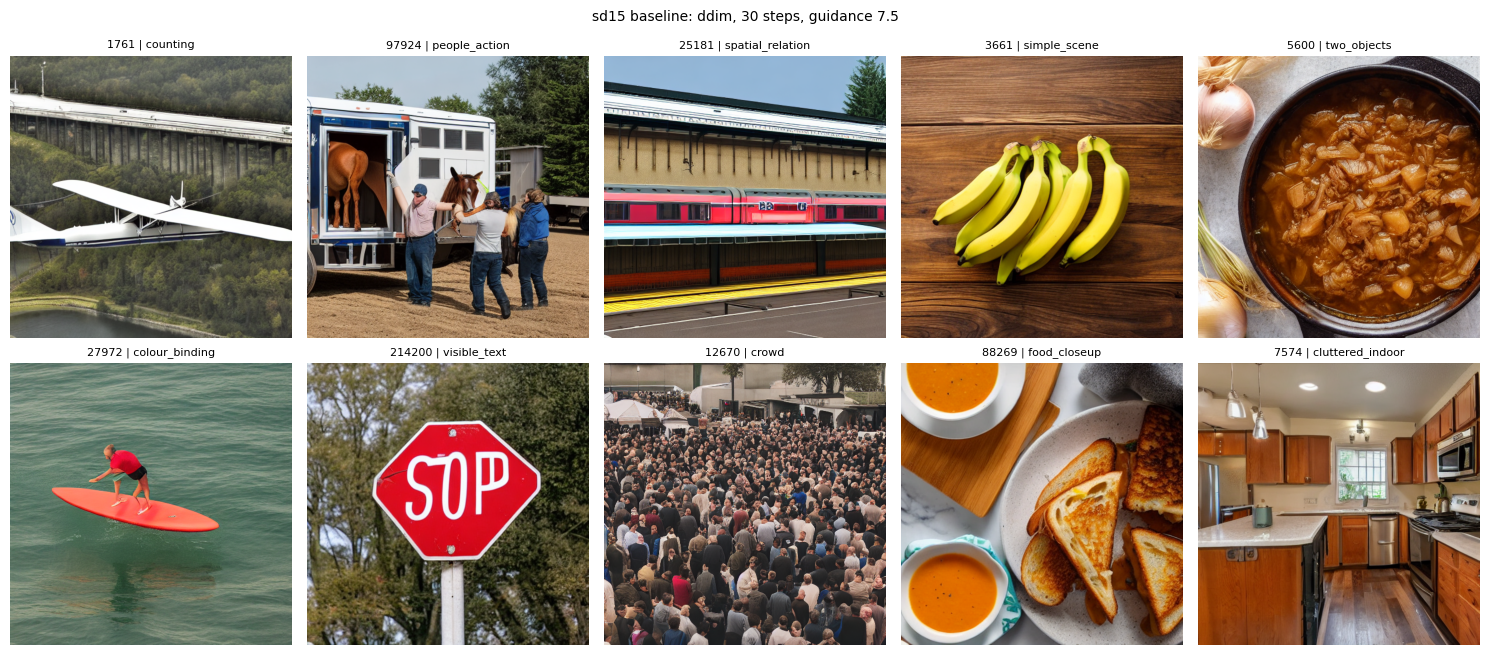

saved baseline_grid_m2_sd15_v1.png


In [32]:
cap = prompts.set_index("image_id")["caption"].to_dict()
seed_of = prompts.set_index("image_id")["seed"].to_dict()

def sheet(items, ncols, title, save):
    nrows = -(-len(items) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 3.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (path, label) in zip(axes.flat, items):
        if path.exists():
            ax.imshow(Image.open(path))
        ax.set_title(label, fontsize=8)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.savefig(save, dpi=120, bbox_inches="tight")
    plt.show()
    print("saved", save.name)

def path_of(iid, sc, st, g):
    return IMG_DIR / fname(iid, sc, st, g, int(seed_of[iid]))

b = BASELINE
sheet([(path_of(i, b["scheduler"], b["steps"], b["guidance"]), f"{i} | {c}")
       for i, c in zip(prompts["image_id"], prompts["category"])],
      5, f"{MODEL_TAG} baseline: {b['scheduler']}, {b['steps']} steps, guidance {b['guidance']}",
      M2_RESULTS / f"baseline_grid_{RUN_TAG}.png")

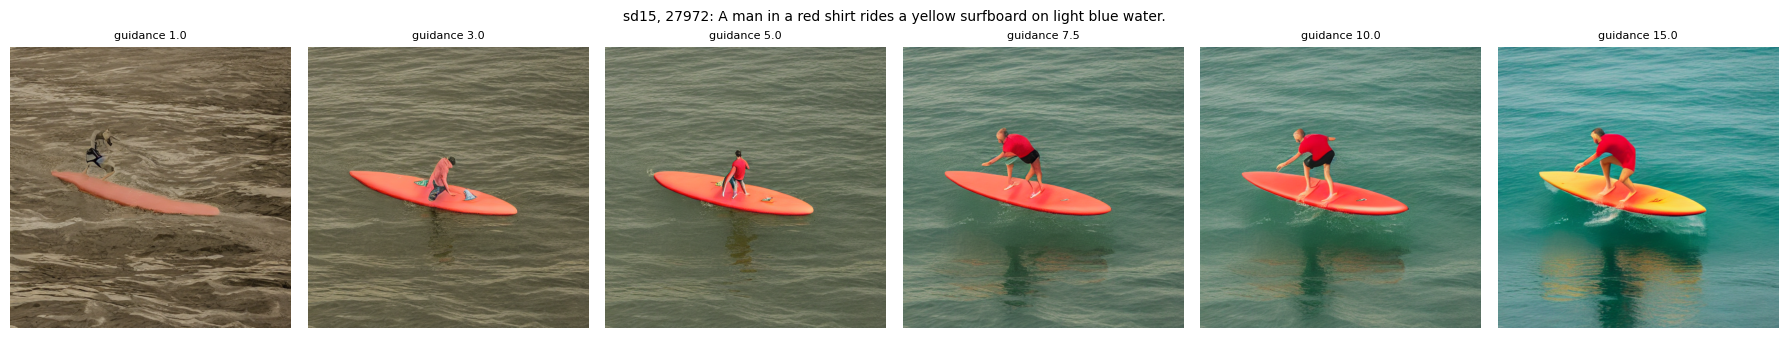

saved strip_guidance_m2_sd15_v1.png


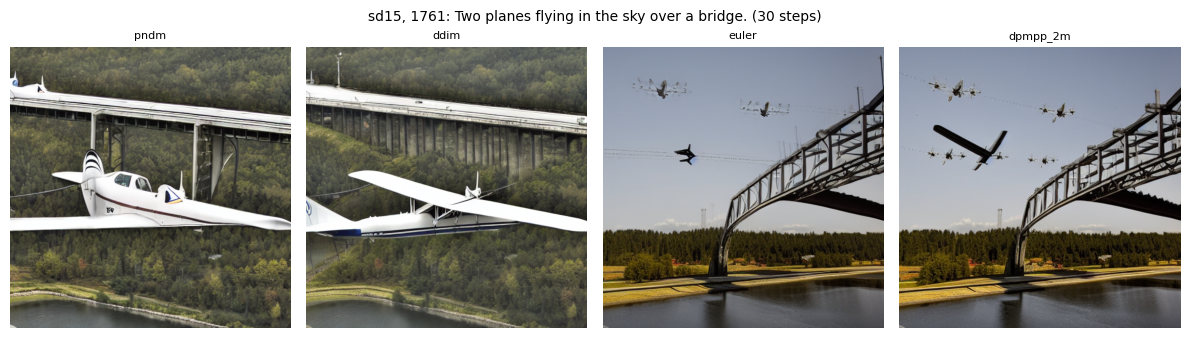

saved strip_scheduler_m2_sd15_v1.png


In [33]:
if "guidance" in RUN_SWEEPS and STRIP_PROMPT_GUIDANCE in seed_of:
    i = STRIP_PROMPT_GUIDANCE
    sheet([(path_of(i, b["scheduler"], b["steps"], g), f"guidance {g}") for g in GUIDANCE_VALUES],
          len(GUIDANCE_VALUES), f"{MODEL_TAG}, {i}: {cap[i][:90]}",
          M2_RESULTS / f"strip_guidance_{RUN_TAG}.png")

if "steps_x_scheduler" in RUN_SWEEPS and STRIP_PROMPT_SCHEDULER in seed_of:
    i = STRIP_PROMPT_SCHEDULER
    sheet([(path_of(i, sc, b["steps"], b["guidance"]), sc) for sc in SCHEDULER_NAMES],
          len(SCHEDULER_NAMES), f"{MODEL_TAG}, {i}: {cap[i][:90]} ({b['steps']} steps)",
          M2_RESULTS / f"strip_scheduler_{RUN_TAG}.png")